# Solving the n-Queens Problem using Local Search
## Lab 04 – Bài 5–8 
Python 3, NumPy, Matplotlib; nếu cần cài: `%pip install numpy matplotlib`.


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

**Sản phẩm theo yêu cầu người dùng/PDF:** notebook `.ipynb` đã chạy đầy đủ. Phần nâng cao được thực hiện thêm; Genetic Algorithm là phần tự chọn ngoài điểm, không thuộc phạm vi bài này.

In [1]:
import platform, time, math, random
from IPython.display import display, Markdown
print('Python:',platform.python_version())

Python: 3.12.14


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

**Mô hình CSP:** biến $X_i$ là hàng của hậu cột i, miền $\{0,\ldots,n-1\}$; ràng buộc $X_i\ne X_j$ và $|X_i-X_j|\ne|i-j|$. Hàm mục tiêu $h=\sum_{i<j}[X_i=X_j\;\lor\;|X_i-X_j|=|i-j|]$. Vì mỗi cột chỉ có một hậu, h=0 khi và chỉ khi không có cặp tấn công. Không gian có $n^n$ trạng thái. Lưu ý phát biểu có nghiệm trong mẫu chỉ đúng với n=1 hoặc n≥4; n=2,3 vô nghiệm.


## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

print('NumPy:', np.__version__)
assert conflicts([1,3,0,2]) == 0
assert conflicts([0,0,0,0]) == 6
assert conflicts([0,1,2,3]) == 6
for size in [4,8]:
    b = random_board(size)
    brute = sum(b[i]==b[j] or abs(int(b[i])-int(b[j]))==j-i
                for i in range(size) for j in range(i+1,size))
    assert conflicts(b) == brute
print('Kiểm tra h bằng đếm từng cặp: đạt.')


NumPy: 2.5.4
Kiểm tra h bằng đếm từng cặp: đạt.


## Create a board

Board with 5 conflicts.


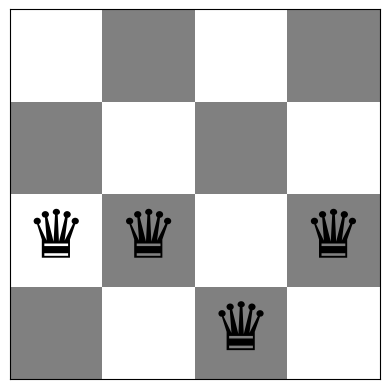

Queens (left to right) are at rows: [2 2 3 2]
Number of conflicts: 5
Board with 9 conflicts.


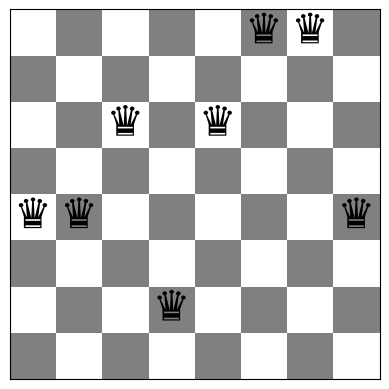

n=8: [4 4 2 6 2 0 0 4] h= 9


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")
board8 = random_board(8)
show_board(board8, fontsize=30)
print("n=8:", board8, "h=", conflicts(board8))

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


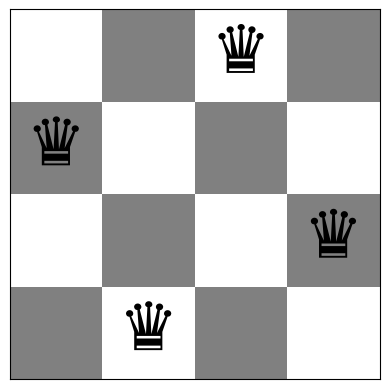

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

Do đang **giảm số xung đột**, steepest-ascent tương ứng chọn mức giảm lớn nhất. Mỗi vòng xét n(n−1) láng giềng, chỉ nhận h giảm nghiêm ngặt. Nếu mọi láng giềng có h≥h hiện tại thì dừng; các trạng thái bằng h không được đi nên có thể kẹt ở plateau. Mỗi lần gọi `conflicts` được tính một đánh giá.

In [5]:
def all_neighbors(board):
    for col in range(len(board)):
        for row in range(len(board)):
            if row != board[col]:
                b = list(board); b[col] = row
                yield b

def hc_search(board, mode='steepest', seed=0):
    rng = random.Random(seed); b = list(board); h = conflicts(b)
    evaluations = 1; steps = 0; history = [h]
    t0 = time.perf_counter()
    while h > 0:
        improving = []
        for candidate in all_neighbors(b):
            value = conflicts(candidate); evaluations += 1
            if value < h: improving.append((value,candidate))
        if not improving: break
        if mode == 'steepest':
            best = min(v for v,_ in improving)
            h,b = rng.choice([(v,c) for v,c in improving if v==best])
        else: h,b = rng.choice(improving)
        steps += 1; history.append(h)
    return dict(board=b,h=h,steps=steps,evaluations=evaluations,history=history,
                seconds=time.perf_counter()-t0,status='solved' if h==0 else 'local_optimum')

def steepest_hc(board,seed=0): return hc_search(board,'steepest',seed)
demo = steepest_hc(board8,42)
print({k:v for k,v in demo.items() if k!='history'})

{'board': [1, 7, np.int32(2), np.int32(6), 3, np.int32(0), np.int32(0), np.int32(4)], 'h': 1, 'steps': 3, 'evaluations': 225, 'seconds': 0.0016384000000471133, 'status': 'local_optimum'}


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.



In [6]:
def inefficient_stochastic_hc(board, seed=0):
    return hc_search(board, 'stochastic', seed)
print(inefficient_stochastic_hc(board8,42))

{'board': [1, 5, np.int32(2), np.int32(6), 3, 7, np.int32(0), np.int32(4)], 'h': 1, 'steps': 5, 'evaluations': 337, 'history': [9, 7, 5, 4, 2, 1], 'seconds': 0.0023719000000710366, 'status': 'local_optimum'}


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

Chọn đều một trong m=n(n−1) nước mỗi lần, có hoàn lại. Dừng sau $L=\lceil m\ln(m/0.01)\rceil$ lần liên tiếp không cải thiện hoặc 20.000 đánh giá. Với trạng thái cố định, xác suất bỏ sót ít nhất một nước sau L lần không quá $m e^{-L/m}\le0.01$ (union bound). Đây là tiêu chí xác suất, không chứng minh cực trị; đặt lại bộ đếm khi nhận nước mới. Mỗi đề xuất chỉ cần một lần đánh giá O(n), nhưng thất bại liên tiếp có thể làm tổng chi phí cao.


In [7]:
def random_neighbor(board, rng):
    n = len(board); b = list(board)
    c = rng.randrange(n); r = rng.randrange(n-1)
    if r >= b[c]: r += 1
    b[c] = r
    return b

def efficient_stochastic_hc(board, seed=0, max_evaluations=20000):
    rng = random.Random(seed); b = list(board); h = conflicts(b)
    n = len(b); m = n*(n-1)
    patience = math.ceil(m*math.log(m/0.01))
    failures = steps = 0; evaluations = 1; history = [h]
    t0=time.perf_counter()
    while h > 0 and failures < patience and evaluations < max_evaluations:
        candidate = random_neighbor(b,rng); value=conflicts(candidate); evaluations+=1
        if value < h: b,h=candidate,value; steps+=1; failures=0
        else: failures+=1
        history.append(h)
    status='solved' if h==0 else ('budget' if evaluations>=max_evaluations else 'patience')
    return dict(board=b,h=h,steps=steps,evaluations=evaluations,history=history,
                seconds=time.perf_counter()-t0,status=status)
print({k:v for k,v in efficient_stochastic_hc(board8,42).items() if k!='history'})

{'board': [1, 6, np.int32(2), 5, 7, 4, np.int32(0), 3], 'h': 0, 'steps': 8, 'evaluations': 51, 'seconds': 0.00047960000028979266, 'status': 'solved'}


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

Tối đa 100 **lần khởi động lại**, tức 101 lần chạy tính cả lần đầu. Dừng ngay khi h=0; nếu hết ngân sách trả bàn tốt nhất và trạng thái `restart_limit`. Tổng bước, đánh giá, thời gian gồm mọi lần đã chạy, không chỉ lần tốt nhất.

In [8]:
HC = {'Steepest HC':steepest_hc, 'Inefficient stochastic HC':inefficient_stochastic_hc,
      'Efficient stochastic HC':efficient_stochastic_hc}
def random_restart(board, base=steepest_hc, seed=0, max_restarts=100):
    rng=random.Random(seed); n=len(board); best=None
    history=[]; steps=evaluations=0; t0=time.perf_counter()
    for restart in range(max_restarts+1):
        start=list(board) if restart==0 else [rng.randrange(n) for _ in range(n)]
        result=base(start,rng.randrange(2**32))
        history.extend(result['history']); steps+=result['steps']; evaluations+=result['evaluations']
        if best is None or result['h']<best['h']: best=result
        if result['h']==0: break
    return dict(board=best['board'],h=best['h'],steps=steps,evaluations=evaluations,
                history=history,restarts=restart,seconds=time.perf_counter()-t0,
                status='solved' if best['h']==0 else 'restart_limit')
for name,fn in HC.items():
    result=random_restart(board8,fn,42)
    print(name, {k:v for k,v in result.items() if k!='history'})

Steepest HC {'board': [4, 2, 0, 5, 7, 1, 3, 6], 'h': 0, 'steps': 42, 'evaluations': 3094, 'restarts': 13, 'seconds': 0.021292200000061712, 'status': 'solved'}
Inefficient stochastic HC {'board': [6, 2, 7, 1, 4, 0, 5, 3], 'h': 0, 'steps': 65, 'evaluations': 4325, 'restarts': 12, 'seconds': 0.028743300000314775, 'status': 'solved'}
Efficient stochastic HC {'board': [0, 4, 7, 5, 2, 6, 1, 3], 'h': 0, 'steps': 10, 'evaluations': 609, 'restarts': 1, 'seconds': 0.005138600000464066, 'status': 'solved'}


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

Hai lịch cùng T đầu=2, T cuối=0,001 và tối đa 5.000 đề xuất: geometric giảm theo tỷ lệ cố định; linear giảm tuyến tính. Với Δh>0 nhận bằng exp(−Δh/T); Δh≤0 luôn nhận. Lưu riêng trạng thái hiện tại và trạng thái tốt nhất: bảng h dùng **tốt nhất**, đồ thị dùng **hiện tại** để thấy các bước tăng h. Không suy ra tối ưu chỉ từ việc hết lịch nhiệt.

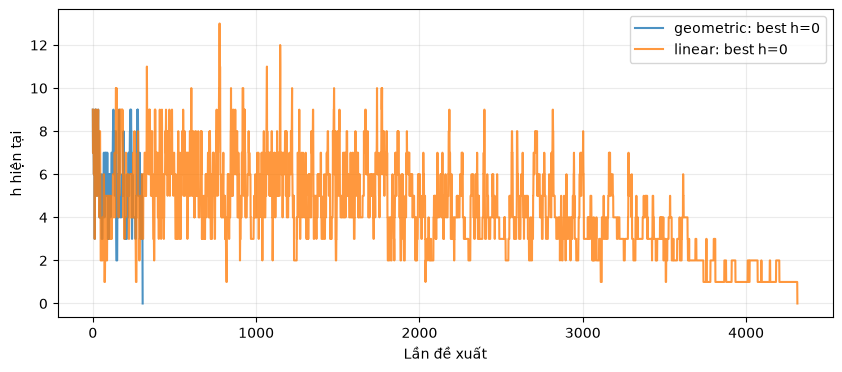

In [9]:
def simulated_annealing(board, seed=0, schedule='geometric', max_steps=5000, t0=2.0, tmin=0.001):
    rng=random.Random(seed); b=list(board); h=conflicts(b)
    best=b.copy(); best_h=h; history=[h]; steps=accepted=uphill=0
    start=time.perf_counter()
    for k in range(max_steps):
        if h==0: break
        if schedule=='geometric': T=t0*(tmin/t0)**(k/max(1,max_steps-1))
        elif schedule=='linear': T=t0+(tmin-t0)*k/max(1,max_steps-1)
        else: raise ValueError('Unknown schedule')
        candidate=random_neighbor(b,rng); value=conflicts(candidate); delta=value-h
        if delta<=0 or rng.random()<math.exp(-delta/T):
            uphill+=int(delta>0); b,h=candidate,value; accepted+=1
        steps+=1; history.append(h)
        if h<best_h: best,best_h=b.copy(),h
    return dict(board=best,h=best_h,current_h=h,steps=steps,evaluations=steps+1,
                history=history,accepted=accepted,uphill=uphill,seconds=time.perf_counter()-start,
                status='solved' if best_h==0 else 'budget')

plt.figure(figsize=(10,4))
for schedule in ['geometric','linear']:
    r=simulated_annealing(board8,42,schedule)
    plt.plot(r['history'],label=f"{schedule}: best h={r['h']}",alpha=.8)
plt.xlabel('Lần đề xuất'); plt.ylabel('h hiện tại'); plt.legend(); plt.grid(alpha=.25); plt.show()

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:



In [10]:
ALGORITHMS = dict(HC)
for label,fn in HC.items():
    ALGORITHMS['RR + '+label] = lambda b,s,fn=fn: random_restart(b,fn,s)
ALGORITHMS['SA geometric'] = lambda b,s: simulated_annealing(b,s,'geometric')
ALGORITHMS['SA linear'] = lambda b,s: simulated_annealing(b,s,'linear')

records=[]
for size in [4,8]:
    starts=[np.random.default_rng(10000+size*100+i).integers(0,size,size).tolist() for i in range(100)]
    for name,fn in ALGORITHMS.items():
        for trial,initial in enumerate(starts):
            r=fn(initial,20000+trial)
            assert r['h']==conflicts(r['board'])
            records.append(dict(n=size,algorithm=name,trial=trial,
                                **{k:v for k,v in r.items() if k not in ['history','board']}))

def mean(rows,key): return float(np.mean([r[key] for r in rows]))
table=['| Algorithm | Board size | Avg. Run time (s) | Avg. conflicts (best for SA/RR) | Success % | Avg. steps | Avg. evaluations | Avg. restarts |',
       '|---|---|---|---|---|---|---|---|']
for size in [4,8]:
    for name in ALGORITHMS:
        rows=[r for r in records if r['n']==size and r['algorithm']==name]
        table.append(f"|{name}|{size}|{mean(rows,'seconds'):.6f}|{mean(rows,'h'):.2f}|{100*np.mean([r['h']==0 for r in rows]):.0f}|{mean(rows,'steps'):.1f}|{mean(rows,'evaluations'):.1f}|{np.mean([r.get('restarts',0) for r in rows]):.2f}|")
display(Markdown('\n'.join(table)))

| Algorithm | Board size | Avg. Run time (s) | Avg. conflicts (best for SA/RR) | Success % | Avg. steps | Avg. evaluations | Avg. restarts |
|---|---|---|---|---|---|---|---|
|Steepest HC|4|0.000114|0.53|54|1.7|26.9|0.00|
|Inefficient stochastic HC|4|0.000145|0.73|38|2.0|33.0|0.00|
|Efficient stochastic HC|4|0.000475|0.68|41|2.1|63.9|0.00|
|RR + Steepest HC|4|0.000385|0.00|100|3.7|60.6|1.20|
|RR + Inefficient stochastic HC|4|0.000513|0.00|100|5.4|90.1|1.87|
|RR + Efficient stochastic HC|4|0.001502|0.00|100|6.2|226.5|2.19|
|SA geometric|4|0.000410|0.00|100|80.6|81.6|0.00|
|SA linear|4|0.000361|0.00|100|81.2|82.2|0.00|
|Steepest HC|8|0.001162|1.25|13|3.2|231.2|0.00|
|Inefficient stochastic HC|8|0.001833|1.40|13|4.9|326.4|0.00|
|Efficient stochastic HC|8|0.004512|1.30|17|5.1|466.9|0.00|
|RR + Steepest HC|8|0.011100|0.00|100|19.9|1414.7|5.28|
|RR + Inefficient stochastic HC|8|0.023002|0.00|100|31.2|2055.5|5.43|
|RR + Efficient stochastic HC|8|0.041292|0.00|100|34.5|3440.7|6.06|
|SA geometric|8|0.016299|0.00|100|1293.3|1294.3|0.00|
|SA linear|8|0.040169|0.05|95|3424.6|3425.6|0.00|

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

HC giảm nhanh giai đoạn đầu rồi dừng ở h>0 nếu không còn bước cải thiện; đường ngắn không đồng nghĩa đã giải được bài. Efficient HC có các đoạn ngang do đề xuất bị từ chối. RR nối lịch sử các lần chạy nên có bước nhảy khi khởi động lại. SA có thể tăng h khi nhiệt cao, sau đó dao động giảm khi nhiệt hạ. Hai lịch dùng cùng bàn/seed, nhưng đường đi có thể khác ngay sau quyết định chấp nhận đầu tiên. So sánh plateau phải đọc cùng đơn vị trục x: HC toàn bộ láng giềng dùng nước được nhận, các phương pháp đề xuất từng láng giềng dùng số lần thử.

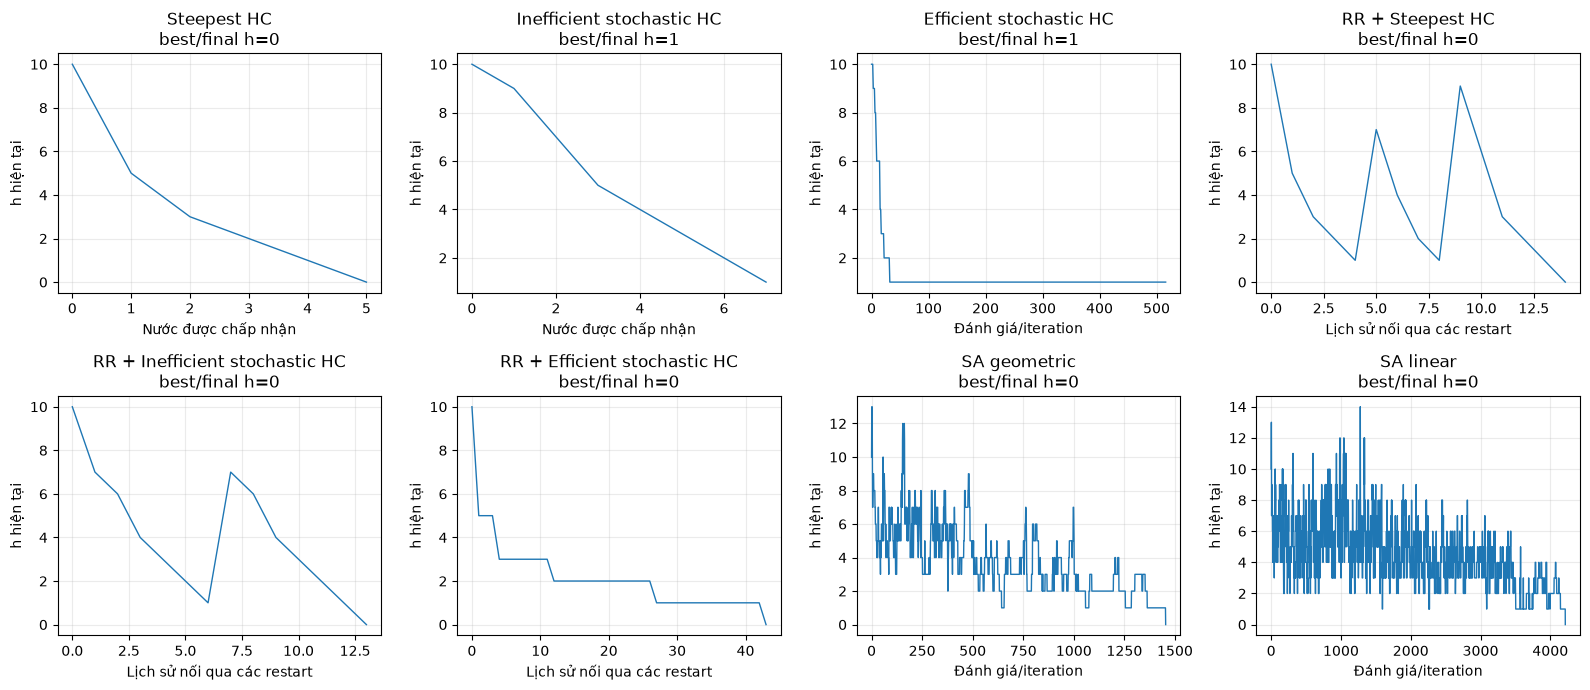

Board with 0 conflicts.


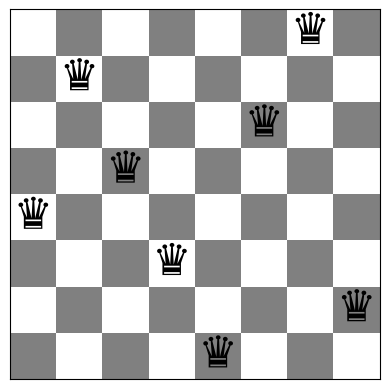

In [11]:
initial=np.random.default_rng(2026).integers(0,8,8).tolist()
fig,axes=plt.subplots(2,4,figsize=(16,7))
for ax,(name,fn) in zip(axes.flat,ALGORITHMS.items()):
    r=fn(initial,123)
    ax.plot(r['history'],linewidth=1)
    ax.set(title=f"{name}\nbest/final h={r['h']}",xlabel='Đánh giá/iteration',ylabel='h hiện tại')
    if name in ['Steepest HC','Inefficient stochastic HC']: ax.set_xlabel('Nước được chấp nhận')
    if name.startswith('RR'): ax.set_xlabel('Lịch sử nối qua các restart')
    ax.grid(alpha=.25)
plt.tight_layout(); plt.show()
solution=random_restart(initial,steepest_hc,123)
assert solution['h']==0
show_board(solution['board'],fontsize=32)

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

`conflicts` dùng bộ đếm hàng/chéo nên O(n), một vòng Steepest/Inefficient xét n(n−1) bàn nên O(n³). Toàn bộ HC còn phụ thuộc số vòng cải thiện. Efficient dùng O(n) mỗi đề xuất nhưng có nhiều lần từ chối và patience tăng khoảng O(n² log n). Hệ số dốc trên log-log chỉ là số mũ **thực nghiệm** trong n=4..20 với tiêu chí dừng này, không chứng minh Big O tổng quát. Thời gian ngắn do kẹt ở nghiệm xấu không phải khả năng mở rộng tốt; đọc kèm tỷ lệ thành công đã in.

Steepest HC : số mũ hồi quy log-log = 4.2
Tỷ lệ h=0 theo n: [np.float64(45.0), np.float64(15.0), np.float64(5.0), np.float64(0.0), np.float64(0.0)]
Efficient stochastic HC : số mũ hồi quy log-log = 3.63
Tỷ lệ h=0 theo n: [np.float64(30.0), np.float64(10.0), np.float64(10.0), np.float64(5.0), np.float64(0.0)]


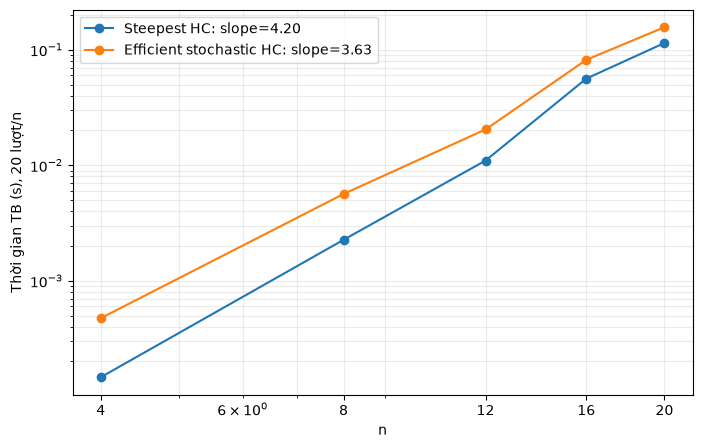

In [12]:
sizes=[4,8,12,16,20]
scale_records=[]
for size in sizes:
    for trial in range(20):
        b=np.random.default_rng(30000+size*100+trial).integers(0,size,size).tolist()
        for name,fn in [('Steepest HC',steepest_hc),('Efficient stochastic HC',efficient_stochastic_hc)]:
            r=fn(b,40000+trial)
            scale_records.append(dict(n=size,algorithm=name,seconds=r['seconds'],h=r['h']))
plt.figure(figsize=(8,5))
for name in ['Steepest HC','Efficient stochastic HC']:
    ys=[mean([r for r in scale_records if r['n']==size and r['algorithm']==name],'seconds') for size in sizes]
    slope=float(np.polyfit(np.log(sizes),np.log(ys),1)[0])
    plt.loglog(sizes,ys,'o-',label=f'{name}: slope={slope:.2f}')
    print(name,': số mũ hồi quy log-log =',round(slope,2))
    print('Tỷ lệ h=0 theo n:',[round(100*np.mean([r['h']==0 for r in scale_records if r['n']==size and r['algorithm']==name]),1) for size in sizes])
plt.xticks(sizes,sizes); plt.xlabel('n'); plt.ylabel('Thời gian TB (s), 20 lượt/n')
plt.legend(); plt.grid(alpha=.25,which='both'); plt.show()

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

**Thiết lập nâng cao:** 100 lượt/toán tử/n ở n=8,12, chung bàn và seed; tối đa 2.000 đề xuất mỗi lượt, dừng sớm khi h=0. Dùng cùng trần thay vì patience vì không gian láng giềng khác nhau. Single-step chỉ đổi một hàng kề, swap hoán đổi hai cột (có thể không đổi bàn nếu cùng hàng), dual đổi đồng thời hai hậu; adaptive 80% chọn hậu nhiều xung đột nhất và 20% dual. Biểu đồ thời gian chỉ tính lượt thành công, không có lượt thành công ghi N/A.

Swap bảo toàn đa tập hàng nên nếu khởi tạo có hàng trùng thì không thể đạt h=0 bằng swap thuần túy; tỷ lệ thành công thấp là hạn chế của toán tử chứ không phải thiếu seed. Single-step hạn chế khả năng vượt chướng ngại; dual mở rộng lân cận nhưng làm hai thay đổi nên dễ phá ràng buộc đang tốt. Adaptive tập trung vào hậu xung đột nhưng thêm chi phí chấm điểm. Cần kết hợp chất lượng, tỷ lệ thành công và thời gian để chọn toán tử theo kết quả thực tế, không chọn chỉ theo một lượt đẹp.


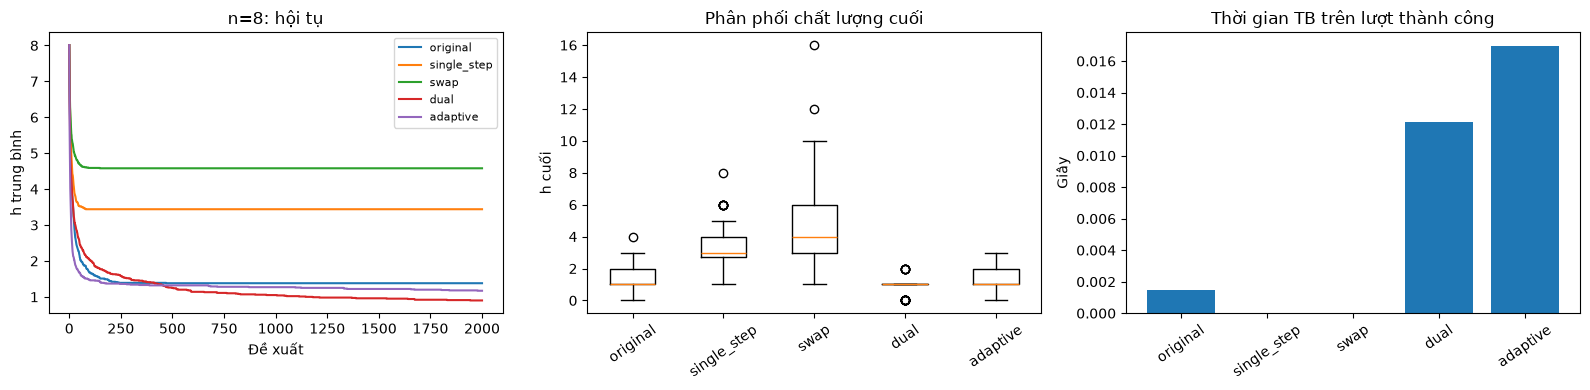

n=8, original: success=12/100, h TB=1.38, time success=0.0015026416666235793
n=8, single_step: success=0/100, h TB=3.44, time success=N/A
n=8, swap: success=0/100, h TB=4.58, time success=N/A
n=8, dual: success=16/100, h TB=0.90, time success=0.012113425000109146
n=8, adaptive: success=16/100, h TB=1.17, time success=0.01697256249997281


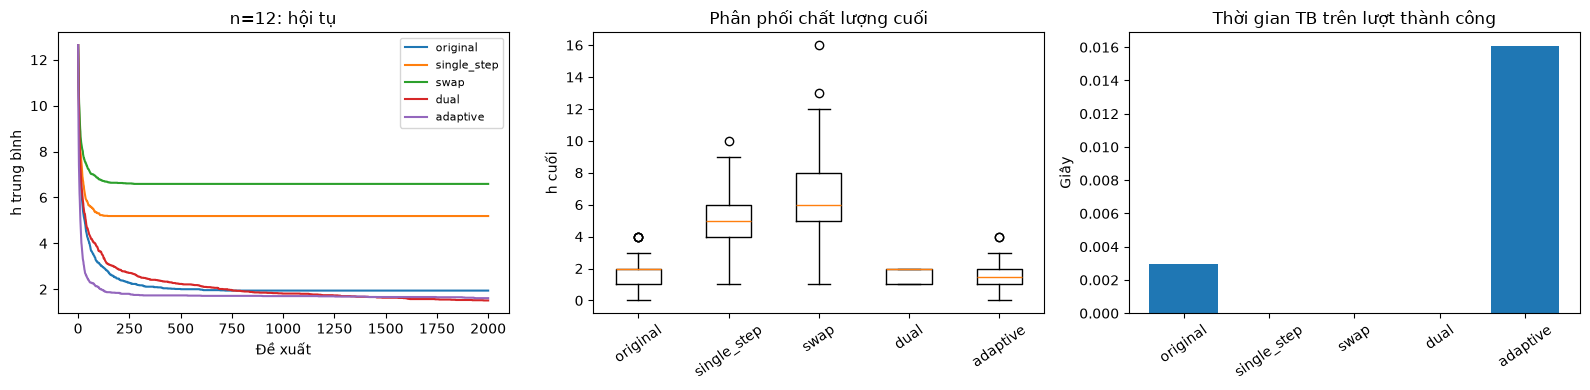

n=12, original: success=1/100, h TB=1.94, time success=0.002968200000395882
n=12, single_step: success=0/100, h TB=5.19, time success=N/A
n=12, swap: success=0/100, h TB=6.59, time success=N/A
n=12, dual: success=0/100, h TB=1.51, time success=N/A
n=12, adaptive: success=9/100, h TB=1.61, time success=0.016091355555545306


In [13]:
def operator_neighbor(board,rng,kind):
    b=list(board); n=len(b)
    if kind=='single_step':
        c=rng.randrange(n); choices=[r for r in (b[c]-1,b[c]+1) if 0<=r<n]
        b[c]=rng.choice(choices)
    elif kind=='swap':
        i,j=rng.sample(range(n),2); b[i],b[j]=b[j],b[i]
    elif kind=='dual':
        for c in rng.sample(range(n),2):
            r=rng.randrange(n-1); b[c]=r+(r>=b[c])
    elif kind=='adaptive':
        scores=[sum(i!=j and (b[i]==b[j] or abs(b[i]-b[j])==abs(i-j)) for j in range(n)) for i in range(n)]
        if rng.random()<0.8:
            c=rng.choice([i for i,s in enumerate(scores) if s==max(scores)])
            r=rng.randrange(n-1); b[c]=r+(r>=b[c])
        else: return operator_neighbor(b,rng,'dual')
    else: return random_neighbor(b,rng)
    return b

def operator_hc(board,kind,seed,max_steps=2000):
    rng=random.Random(seed); b=list(board); h=conflicts(b); history=[h]
    t0=time.perf_counter()
    for step in range(max_steps):
        if h==0: break
        candidate=operator_neighbor(b,rng,kind); value=conflicts(candidate)
        if value<h: b,h=candidate,value
        history.append(h)
    return dict(h=h,history=history,seconds=time.perf_counter()-t0)

operator_records=[]
kinds=['original','single_step','swap','dual','adaptive']
for size in [8,12]:
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for kind in kinds:
        runs=[]
        for trial in range(100):
            b=np.random.default_rng(50000+100*size+trial).integers(0,size,size).tolist()
            r=operator_hc(b,kind,60000+trial); runs.append(r)
        # Sau khi dừng, giữ h cuối để trung bình trên cùng trục và đủ 100 lượt.
        padded=[np.pad(r['history'],(0,2001-len(r['history'])),constant_values=r['h']) for r in runs]
        axes[0].plot(np.mean(padded,axis=0),label=kind)
        operator_records.append((size,kind,runs))
    selected=[x for x in operator_records if x[0]==size]
    axes[1].boxplot([[r['h'] for r in runs] for _,_,runs in selected],tick_labels=kinds)
    success_times=[np.mean([r['seconds'] for r in runs if r['h']==0]) if any(r['h']==0 for r in runs) else np.nan for _,_,runs in selected]
    axes[2].bar(kinds,success_times)
    axes[0].set(xlabel='Đề xuất',ylabel='h trung bình',title=f'n={size}: hội tụ'); axes[0].legend(fontsize=8)
    axes[1].set(ylabel='h cuối',title='Phân phối chất lượng cuối')
    axes[2].set(ylabel='Giây',title='Thời gian TB trên lượt thành công')
    for ax in axes[1:]: ax.tick_params(axis='x',rotation=35)
    plt.tight_layout(); plt.show()
    for _,kind,runs in selected:
        successes=[r for r in runs if r['h']==0]
        print(f'n={size}, {kind}: success={len(successes)}/100, h TB={np.mean([r["h"] for r in runs]):.2f}, time success={np.mean([r["seconds"] for r in successes]) if successes else "N/A"}')

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

Phần Genetic Algorithm nằm trong “More Things to Do (not for credit)” của mẫu, không thuộc các Task 1–6 hoặc yêu cầu PDF nên không triển khai trong bài nộp này.

### Tổng kết và câu hỏi thảo luận 4–6
* Hill Climbing chỉ nhận h giảm nên không vượt được thung lũng có bước trung gian xấu hơn, và dừng khi chỉ còn nước bằng h. RR thay điểm xuất phát; SA nhận bước xấu với xác suất phụ thuộc nhiệt độ. Không phương pháp hữu hạn ngẫu nhiên nào ở đây chứng minh vô nghiệm khi thất bại.
* Steepest và Inefficient Stochastic tính toàn bộ n(n−1) láng giềng mỗi vòng; khác ở chọn tốt nhất hay ngẫu nhiên trong các bước cải thiện. Efficient chỉ tính một láng giềng mỗi đề xuất, nhưng có thể thử nhiều lần và dừng xác suất. So sánh phải dựa trên tổng đánh giá, không gọi mọi loại “bước” là chi phí như nhau.
* Nhiều lượt giảm phụ thuộc khởi tạo và seed; chung dữ liệu, tiêu chí dừng rõ ràng, tính cả thất bại giúp tránh chọn kết quả thuận lợi. Tỷ lệ thành công là ước lượng từ mẫu hữu hạn; máy, phiên bản thư viện, thu thập lịch sử và ngân sách đều ảnh hưởng thời gian. Các seed cố định giúp tái tạo chất lượng, không làm thời gian hoàn toàn giống nhau.

### Nhận xét dựa trên kết quả đã lưu
Ở n=4, ba HC đơn lẻ đạt 54%, 38%, 41%; ở n=8 đạt 13%, 13%, 17%. Việc Efficient có tỷ lệ cao hơn ở mẫu n=8 không đủ kết luận ưu thế thống kê; nó còn dùng trung bình 466,9 đánh giá so với 231,2 của Steepest. Cả ba phiên bản RR đạt 100/100 tại n=4 và n=8 trong ngân sách; n=8 dùng trung bình 5,28–6,06 restart. Đây là kết quả thực nghiệm, không là bảo đảm mọi seed đều thành công.

SA geometric tại n=8 đạt 100/100, trung bình 1.293,3 đề xuất, so với linear 95/100 và 3.424,6 đề xuất. Lịch geometric giảm nhiệt nhanh hơn ở giai đoạn đầu của thiết lập này nên ổn định sớm hơn; linear duy trì nhiễu lâu hơn. Một hình đại diện không thay thế thống kê nhiều lượt.

Trên khảo sát n=4,8,12,16,20, dốc thời gian log-log Steepest khoảng 4,20 và Efficient khoảng 3,63. Efficient tăng chậm hơn theo n trong lần đo này, nhưng thời gian tuyệt đối còn phụ thuộc patience và nhiều lần từ chối; cả hai đều thất bại 20/20 ở n=20 nên không thể gọi là giải tốt bài lớn.

Ở phần nâng cao, n=8 toán tử gốc/dual/adaptive lần lượt đạt 12/16/16%, single-step và swap đạt 0%. Ở n=12, adaptive đạt 9%, gốc đạt 1%, các toán tử còn lại 0%. Dual có h trung bình thấp (1,51 ở n=12) nhưng không tìm được nghiệm nào; chất lượng gần nghiệm và tỷ lệ giải thành công là hai chỉ số khác nhau. Adaptive cải thiện tỷ lệ trong mẫu n=12 với chi phí đánh giá hậu xung đột. Single-step hạn chế lân cận, swap không sửa được hàng trùng. Nên thử thêm seed/ngân sách trước khi khái quát các kết luận.

Các nhận xét số cụ thể mô tả đầu ra đã lưu; khi thay cấu hình hoặc seed cần cập nhật lại theo bảng mới.
